<a href="https://colab.research.google.com/github/suhanigupta786/T004-Flight-Club/blob/main/04_Deep_Learning_Training_Hyperparameter_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 – Deep Learning Training and Hyperparameter Tuning

## 1. Introduction

This notebook focuses on training and optimising the Embedding + MLP architecture developed in Notebook 03.

The objective is to train a PyTorch neural network for flight delay prediction and identify a suitable set of hyperparameters that provides good generalisation performance.

The training pipeline will include:

- Training and validation loops.
- Binary Cross Entropy with Logits loss.
- Class weighting to address target imbalance.
- AdamW optimisation.
- Experiments with learning rates and batch sizes.
- Experiments with hidden layer dimensions and dropout rates.
- Training and validation loss monitoring.
- Early stopping based on validation loss.
- Saving the best model checkpoint.

The training dataset will be used to update model parameters, while the validation dataset will be used for hyperparameter selection and monitoring.

The independent test dataset will remain untouched and will be reserved for the evaluation stage.


## 2. Importing Required Libraries

We use PyTorch for model training, loss calculation, gradient computation and optimisation.

Scikit-learn utilities will be used only where necessary for organising the input data. Matplotlib will be used to visualise training and validation loss curves.

The AdamW optimiser will be used to update the model parameters during training.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import json
import os
import copy
import itertools
import random

from torch.utils.data import TensorDataset, DataLoader

print("PyTorch:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

PyTorch: 2.14.1+cpu
Selected device: cpu


## 3. Loading Preprocessed Data and Model Architecture

This section loads the outputs generated by the previous team members.

The preprocessed dataset from Member 1 contains numerical and categorical tensors along with their corresponding labels and category mappings.

The architecture developed by Member 2 is imported through the `FlightDelayMLP` class.

The model configuration provides the initial embedding dimensions, hidden layer sizes and dropout rates.

These components will be used to initialise the network before training.

In [2]:
from google.colab import files

uploaded = files.upload()

Saving dl_data.pt to dl_data.pt
Saving model.py to model.py
Saving model_config.json to model_config.json


In [3]:
data = torch.load(
    "dl_data.pt",
    map_location="cpu",
    weights_only=False
)

with open("model_config.json", "r") as file:
    config = json.load(file)

from model import FlightDelayMLP

print("Dataset loaded.")
print("Model configuration loaded.")
print("Available dataset keys:", list(data.keys()))

Dataset loaded.
Model configuration loaded.
Available dataset keys: ['X_train_num', 'X_train_cat', 'y_train', 'X_val_num', 'X_val_cat', 'y_val', 'X_test_num', 'X_test_cat', 'y_test', 'numerical_features', 'categorical_features', 'category_maps', 'train_medians', 'scaler_mean', 'scaler_std']


In [4]:
X_train_num = data["X_train_num"].float()
X_train_cat = data["X_train_cat"].long()
y_train = data["y_train"].float().view(-1)

X_val_num = data["X_val_num"].float()
X_val_cat = data["X_val_cat"].long()
y_val = data["y_val"].float().view(-1)

numerical_features = data["numerical_features"]
categorical_features = data["categorical_features"]

category_sizes = config["category_sizes"]
embedding_dims = config["embedding_dimensions"]

print("Training numerical:", X_train_num.shape)
print("Training categorical:", X_train_cat.shape)
print("Training labels:", y_train.shape)

print("\nValidation numerical:", X_val_num.shape)
print("Validation categorical:", X_val_cat.shape)
print("Validation labels:", y_val.shape)

Training numerical: torch.Size([217727, 17])
Training categorical: torch.Size([217727, 4])
Training labels: torch.Size([217727])

Validation numerical: torch.Size([55628, 17])
Validation categorical: torch.Size([55628, 4])
Validation labels: torch.Size([55628])


## 4. Input Data Verification

Before training, we verify that the training and validation tensors have compatible dimensions and data types.

We also check that the categorical indices fall within the embedding table ranges defined by Member 2.

These checks help prevent dimension mismatches and invalid embedding index errors during training.

In [5]:
assert X_train_num.shape[1] == config["numerical_input_dim"]

assert X_train_cat.shape[1] == len(categorical_features)

assert X_train_num.shape[0] == X_train_cat.shape[0] == y_train.shape[0]

assert X_val_num.shape[0] == X_val_cat.shape[0] == y_val.shape[0]

assert torch.isfinite(X_train_num).all()
assert torch.isfinite(X_val_num).all()

for i, feature in enumerate(categorical_features):

    assert X_train_cat[:, i].min() >= 0
    assert X_train_cat[:, i].max() < category_sizes[feature]

    assert X_val_cat[:, i].min() >= 0
    assert X_val_cat[:, i].max() < category_sizes[feature]

print("All training and validation inputs verified!")

All training and validation inputs verified!


## 5. Preparing Training and Validation DataLoaders

We use PyTorch's TensorDataset to combine numerical features, categorical features and their corresponding target labels.

DataLoaders divide the datasets into smaller batches for efficient processing.

The training DataLoader will shuffle the samples during each epoch, whereas the validation DataLoader will preserve the original order.

The batch size will remain configurable because it is one of the hyperparameters we intend to experiment with.

In [6]:
train_dataset = TensorDataset(
    X_train_num,
    X_train_cat,
    y_train
)

val_dataset = TensorDataset(
    X_val_num,
    X_val_cat,
    y_val
)

def create_loaders(batch_size):

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, val_loader

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 217727
Validation samples: 55628


## 6. Handling Class Imbalance

Flight delay datasets may contain an unequal distribution of delayed and non-delayed flights.

If the model is trained without considering this imbalance, it may give more importance to the majority class.

We will use Binary Cross Entropy with Logits Loss (`BCEWithLogitsLoss`) as the initial loss function.

We will experiment with class weighting using the positive class weight:

\[
pos\_weight = \frac{N_{\text{negative}}}{N_{\text{positive}}}
\]

This gives greater importance to delayed flights when calculating the loss.

The class weights will be calculated exclusively from the training labels to avoid information leakage.

In [7]:
positive_count = (y_train == 1).sum().item()
negative_count = (y_train == 0).sum().item()

positive_weight = negative_count / positive_count

print("Positive samples:", positive_count)
print("Negative samples:", negative_count)
print("Positive class weight:", round(positive_weight, 4))

Positive samples: 55765
Negative samples: 161962
Positive class weight: 2.9044


In [8]:
pos_weight = torch.tensor(
    [positive_weight],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("Weighted BCEWithLogitsLoss initialized.")

Weighted BCEWithLogitsLoss initialized.


In [9]:
unweighted_criterion = nn.BCEWithLogitsLoss()

print("Unweighted BCEWithLogitsLoss initialized.")

Unweighted BCEWithLogitsLoss initialized.


## 7. Defining Training Hyperparameters

Hyperparameters are settings that control the learning process and are specified before model training.

We will experiment with:

- **Learning Rate:** Controls the size of parameter updates.
- **Batch Size:** Determines the number of samples processed in one iteration.
- **Hidden Layer Dimensions:** Controls the number of neurons in each hidden layer.
- **Dropout Rates:** Controls the proportion of neurons randomly deactivated during training.
- **Class Weighting:** Determines whether additional importance is assigned to delayed flights.

AdamW will be used as the optimizer across the experiments.

A controlled set of experiments will help us understand how these configurations affect validation loss and select the best-performing training setup.

In [10]:
experiments = [
    {
        "name": "baseline",
        "learning_rate": 0.001,
        "batch_size": 512,
        "hidden_dims": [128, 64, 32],
        "dropout_rates": [0.3, 0.2],
        "class_weighting": True
    },
    {
        "name": "lower_learning_rate",
        "learning_rate": 0.0005,
        "batch_size": 512,
        "hidden_dims": [128, 64, 32],
        "dropout_rates": [0.3, 0.2],
        "class_weighting": True
    },
    {
        "name": "larger_batch",
        "learning_rate": 0.001,
        "batch_size": 1024,
        "hidden_dims": [128, 64, 32],
        "dropout_rates": [0.3, 0.2],
        "class_weighting": True
    },
    {
        "name": "larger_architecture",
        "learning_rate": 0.001,
        "batch_size": 512,
        "hidden_dims": [256, 128, 64],
        "dropout_rates": [0.4, 0.3],
        "class_weighting": True
    },
    {
        "name": "unweighted_loss",
        "learning_rate": 0.001,
        "batch_size": 512,
        "hidden_dims": [128, 64, 32],
        "dropout_rates": [0.3, 0.2],
        "class_weighting": False
    }
]

print("Total experiments:", len(experiments))

for experiment in experiments:
    print("\n", experiment)

Total experiments: 5

 {'name': 'baseline', 'learning_rate': 0.001, 'batch_size': 512, 'hidden_dims': [128, 64, 32], 'dropout_rates': [0.3, 0.2], 'class_weighting': True}

 {'name': 'lower_learning_rate', 'learning_rate': 0.0005, 'batch_size': 512, 'hidden_dims': [128, 64, 32], 'dropout_rates': [0.3, 0.2], 'class_weighting': True}

 {'name': 'larger_batch', 'learning_rate': 0.001, 'batch_size': 1024, 'hidden_dims': [128, 64, 32], 'dropout_rates': [0.3, 0.2], 'class_weighting': True}

 {'name': 'larger_architecture', 'learning_rate': 0.001, 'batch_size': 512, 'hidden_dims': [256, 128, 64], 'dropout_rates': [0.4, 0.3], 'class_weighting': True}

 {'name': 'unweighted_loss', 'learning_rate': 0.001, 'batch_size': 512, 'hidden_dims': [128, 64, 32], 'dropout_rates': [0.3, 0.2], 'class_weighting': False}


## 8. Training Loop Implementation

The training loop performs the following operations for every batch:

1. Load numerical and categorical inputs.
2. Pass the inputs through the MLP.
3. Calculate the loss using BCEWithLogitsLoss.
4. Clear previously accumulated gradients.
5. Perform backpropagation.
6. Update model parameters using the AdamW optimizer.

The training loss is accumulated across batches and averaged over the complete training dataset for each epoch.

The model parameters are updated only during the training phase.

## 9. Validation Loop Implementation

The validation loop measures how well the model performs on data that is not used for updating its parameters.

During validation:

- The model is switched to evaluation mode.
- Gradient calculation is disabled.
- The validation loss is calculated across all validation batches.
- Model parameters remain unchanged.

The average validation loss is used to monitor generalisation performance and determine whether the model is improving.

In [11]:
def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0

    for num_batch, cat_batch, targets in loader:

        num_batch = num_batch.to(device)
        cat_batch = cat_batch.to(device)
        targets = targets.to(device).float()

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            logits = model(num_batch, cat_batch)

            loss = criterion(logits, targets)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * targets.size(0)

    return total_loss / len(loader.dataset)

## 10. Optimisation and Early Stopping

We use the AdamW optimiser to update the neural network parameters.

AdamW combines adaptive gradient optimisation with decoupled weight decay, helping control model complexity.

Early stopping is implemented using validation loss.

If validation loss does not improve for a predefined number of consecutive epochs, training is stopped.

Whenever validation loss improves, the corresponding model parameters are saved as the best checkpoint.

This prevents the final model from being selected solely on the basis of its last training epoch.

In [12]:
unweighted_criterion = nn.BCEWithLogitsLoss()

In [13]:

def train_experiment(
    experiment,
    max_epochs=20,
    patience=4
):

    train_loader, val_loader = create_loaders(
        experiment["batch_size"]
    )

    model = FlightDelayMLP(
        numerical_input_dim=config["numerical_input_dim"],
        category_sizes=category_sizes,
        embedding_dims=embedding_dims,
        hidden_dims=tuple(experiment["hidden_dims"]),
        dropout_rates=tuple(experiment["dropout_rates"])
    ).to(device)

    if experiment["class_weighting"]:
        criterion = nn.BCEWithLogitsLoss(
            pos_weight=pos_weight
        )
    else:
        criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=experiment["learning_rate"],
        weight_decay=1e-4
    )

    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0

    train_history = []
    val_history = []

    best_state = None

    for epoch in range(max_epochs):

        train_loss = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        # Use the same validation objective for every experiment
        val_loss = run_epoch(
            model,
            val_loader,
            unweighted_criterion
        )

        train_history.append(train_loss)
        val_history.append(val_loss)

        print(
            f"Epoch {epoch+1}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {val_loss:.4f}"
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:

            print("Early stopping triggered.")
            break

    return {
        "experiment": experiment,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "train_history": train_history,
        "val_history": val_history,
        "best_state": best_state
    }


## 11. Hyperparameter Experiments

We now train separate instances of the Embedding + MLP architecture using the configurations defined earlier.

Each experiment starts with newly initialised model parameters.

We compare the experiments using their minimum validation loss and corresponding best epoch.

The configuration with the lowest validation loss will be selected as the best training configuration.

The test dataset is not used during this process.

In [14]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

experiment_results = []

for experiment in experiments:

    print("\n" + "=" * 60)
    print("Running experiment:", experiment["name"])
    print("=" * 60)

    result = train_experiment(
        experiment,
        max_epochs=20,
        patience=4
    )

    experiment_results.append(result)

    print(
        f"Best validation loss: {result['best_val_loss']:.4f}"
    )

    print(
        f"Best epoch: {result['best_epoch']}"
    )


Running experiment: baseline
Epoch 1/20 | Train Loss: 0.9678 | Validation Loss: 0.6500
Epoch 2/20 | Train Loss: 0.9529 | Validation Loss: 0.5908
Epoch 3/20 | Train Loss: 0.9469 | Validation Loss: 0.5714
Epoch 4/20 | Train Loss: 0.9420 | Validation Loss: 0.5361
Epoch 5/20 | Train Loss: 0.9369 | Validation Loss: 0.5281
Epoch 6/20 | Train Loss: 0.9332 | Validation Loss: 0.5346
Epoch 7/20 | Train Loss: 0.9287 | Validation Loss: 0.5177
Epoch 8/20 | Train Loss: 0.9252 | Validation Loss: 0.4900
Epoch 9/20 | Train Loss: 0.9220 | Validation Loss: 0.5031
Epoch 10/20 | Train Loss: 0.9184 | Validation Loss: 0.4728
Epoch 11/20 | Train Loss: 0.9145 | Validation Loss: 0.4958
Epoch 12/20 | Train Loss: 0.9118 | Validation Loss: 0.4976
Epoch 13/20 | Train Loss: 0.9077 | Validation Loss: 0.4725
Epoch 14/20 | Train Loss: 0.9059 | Validation Loss: 0.5095
Epoch 15/20 | Train Loss: 0.9028 | Validation Loss: 0.5238
Epoch 16/20 | Train Loss: 0.9007 | Validation Loss: 0.5337
Epoch 17/20 | Train Loss: 0.8991 | 

## 12. Comparing Hyperparameter Experiments

After completing the experiments, we compare their best validation losses.

This comparison helps identify which combination of learning rate, batch size, hidden layer dimensions, dropout rates and class weighting performs best on the validation dataset.

The lowest validation loss will be used as the primary selection criterion for the best training configuration.

In [15]:
results_table = []

for result in experiment_results:

    exp = result["experiment"]

    results_table.append({
        "Experiment": exp["name"],
        "Learning Rate": exp["learning_rate"],
        "Batch Size": exp["batch_size"],
        "Hidden Dimensions": str(exp["hidden_dims"]),
        "Dropout Rates": str(exp["dropout_rates"]),
        "Class Weighting": exp["class_weighting"],
        "Best Epoch": result["best_epoch"],
        "Best Validation Loss": result["best_val_loss"]
    })

results_df = pd.DataFrame(results_table)

results_df = results_df.sort_values(
    by="Best Validation Loss"
).reset_index(drop=True)

display(results_df)

,Experiment,Learning Rate,Batch Size,Hidden Dimensions,Dropout Rates,Class Weighting,Best Epoch,Best Validation Loss
0,unweighted_loss,0.0010,512,"[128, 64, 32]","[0.3, 0.2]",False,5,0.416221
1,larger_batch,0.0010,1024,"[128, 64, 32]","[0.3, 0.2]",True,13,0.459998
2,baseline,0.0010,512,"[128, 64, 32]","[0.3, 0.2]",True,13,0.472461
3,larger_architecture,0.0010,512,"[256, 128, 64]","[0.4, 0.3]",True,8,0.483439
4,lower_learning_rate,0.0005,512,"[128, 64, 32]","[0.3, 0.2]",True,10,0.504026


In [16]:
best_result = min(
    experiment_results,
    key=lambda result: result["best_val_loss"]
)

best_hyperparameters = best_result["experiment"]

print("BEST EXPERIMENT")
print("----------------")

print("Name:", best_hyperparameters["name"])
print("Learning Rate:", best_hyperparameters["learning_rate"])
print("Batch Size:", best_hyperparameters["batch_size"])
print("Hidden Dimensions:", best_hyperparameters["hidden_dims"])
print("Dropout Rates:", best_hyperparameters["dropout_rates"])
print("Class Weighting:", best_hyperparameters["class_weighting"])

print("Best Epoch:", best_result["best_epoch"])
print("Best Validation Loss:", best_result["best_val_loss"])

BEST EXPERIMENT
----------------
Name: unweighted_loss
Learning Rate: 0.001
Batch Size: 512
Hidden Dimensions: [128, 64, 32]
Dropout Rates: [0.3, 0.2]
Class Weighting: False
Best Epoch: 5
Best Validation Loss: 0.41622072338260735


## 13. Saving the Best Model Checkpoint

After comparing all training configurations, we save the model checkpoint corresponding to the lowest validation loss.

The checkpoint contains:

- Best model weights.
- Selected hyperparameters.
- Embedding configuration.
- Numerical and categorical feature information.
- Best validation loss.
- Best training epoch.

This checkpoint will be passed to Member 4 for model evaluation and calibration.

No test-set predictions or evaluation metrics are generated in this section.

In [17]:
os.makedirs("dl_training_outputs", exist_ok=True)

best_checkpoint = {
    "model_state_dict": best_result["best_state"],

    "model_name": "FlightDelayMLP",

    "numerical_input_dim": config["numerical_input_dim"],

    "category_sizes": category_sizes,

    "embedding_dims": embedding_dims,

    "numerical_features": numerical_features,

    "categorical_features": categorical_features,

    "hidden_dims": best_hyperparameters["hidden_dims"],

    "dropout_rates": best_hyperparameters["dropout_rates"],

    "learning_rate": best_hyperparameters["learning_rate"],

    "batch_size": best_hyperparameters["batch_size"],

    "class_weighting": best_hyperparameters["class_weighting"],

    "positive_class_weight": (
        positive_weight
        if best_hyperparameters["class_weighting"]
        else None
    ),

    "best_validation_loss": best_result["best_val_loss"],

    "best_epoch": best_result["best_epoch"]
}

torch.save(
    best_checkpoint,
    "dl_training_outputs/best_model_checkpoint.pth"
)

print("Best model checkpoint saved successfully!")

Best model checkpoint saved successfully!


## 14. Training and Validation Loss Visualization

Training and validation loss curves help us understand the learning behaviour of the selected model.

The training loss represents the error calculated on the training dataset, whereas validation loss represents the error on unseen validation samples.

The curves help us observe:

- Whether the model is learning.
- Whether validation performance improves.
- Whether overfitting may be occurring.
- The epoch at which the best validation performance is achieved.

We plot the loss curves for the selected experiment and preserve the figure as part of the training outputs.

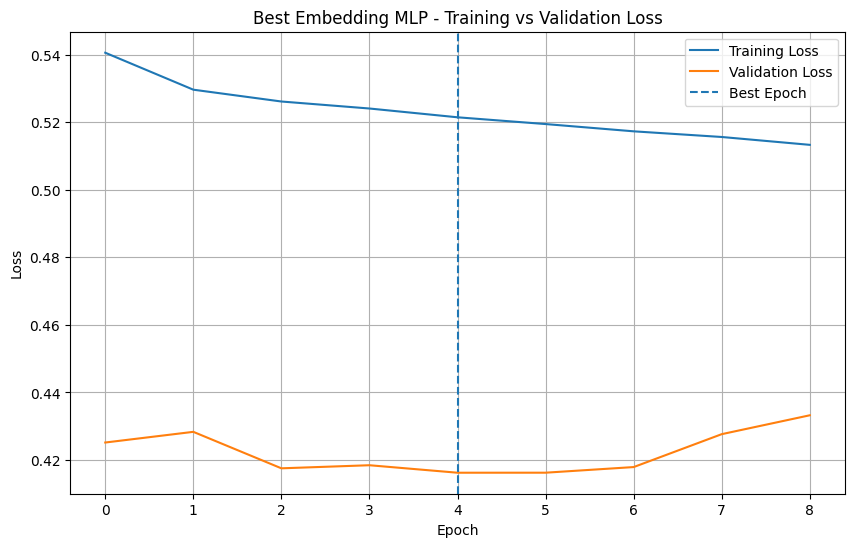

In [18]:
plt.figure(figsize=(10, 6))

plt.plot(
    best_result["train_history"],
    label="Training Loss"
)

plt.plot(
    best_result["val_history"],
    label="Validation Loss"
)

plt.axvline(
    best_result["best_epoch"] - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Best Embedding MLP - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig(
    "dl_training_outputs/best_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 15. Recording Experiment Results

This section consolidates the outcomes of all hyperparameter experiments.

We record the selected hyperparameters, best validation loss, best epoch, and training history.

The results provide a reproducible record of the training process and allow the next team member to understand which configuration produced the selected checkpoint.

All experiment configurations and their corresponding validation results are saved for future reference.

In [19]:
experiment_records = []

for result in experiment_results:

    record = {
        "experiment": result["experiment"],
        "best_validation_loss": result["best_val_loss"],
        "best_epoch": result["best_epoch"],
        "training_loss": result["train_history"],
        "validation_loss": result["val_history"]
    }

    experiment_records.append(record)

with open(
    "dl_training_outputs/training_history.json",
    "w"
) as file:

    json.dump(experiment_records, file, indent=4)

print("Training history saved!")

Training history saved!


In [20]:
final_training_config = {
    "best_hyperparameters": best_hyperparameters,
    "best_validation_loss": best_result["best_val_loss"],
    "best_epoch": best_result["best_epoch"],
    "optimizer": "AdamW",
    "weight_decay": 0.0001,
    "loss_function": "BCEWithLogitsLoss",
    "early_stopping_patience": 4,
    "maximum_epochs": 20,
    "number_of_experiments": len(experiment_results)
}

with open(
    "dl_training_outputs/best_hyperparameters.json",
    "w"
) as file:

    json.dump(final_training_config, file, indent=4)

print("Best hyperparameters saved!")

Best hyperparameters saved!


In [21]:
results_df.to_csv(
    "dl_training_outputs/experiment_comparison.csv",
    index=False
)

print("Experiment comparison saved!")

Experiment comparison saved!


## 16. Final Training Pipeline Summary

The training and hyperparameter tuning pipeline has been completed.

The best-performing configuration has been selected using validation loss, and its model checkpoint has been saved.

The training history, selected hyperparameters, experiment comparison and loss visualisation are preserved for subsequent model evaluation.

The resulting artifacts will be handed over to Member 4 for independent test evaluation and calibration.

In [22]:
print("=" * 55)
print("FLIGHT DELAY PREDICTION - MEMBER 3 SUMMARY")
print("=" * 55)

print("Experiments completed:", len(experiment_results))

print("Best experiment:", best_hyperparameters["name"])

print("Best validation loss:", best_result["best_val_loss"])

print("Best epoch:", best_result["best_epoch"])

print("\nSaved deliverables:")

for filename in os.listdir("dl_training_outputs"):
    print("-", filename)

print("\nTraining pipeline completed successfully!")

FLIGHT DELAY PREDICTION - MEMBER 3 SUMMARY
Experiments completed: 5
Best experiment: unweighted_loss
Best validation loss: 0.41622072338260735
Best epoch: 5

Saved deliverables:
- best_model_checkpoint.pth
- best_training_loss.png
- training_history.json
- best_hyperparameters.json
- experiment_comparison.csv

Training pipeline completed successfully!


In [23]:
import shutil

archive_path = shutil.make_archive(
    "DL_Training_Results",
    "zip",
    "dl_training_outputs"
)

print("Final training archive:", archive_path)

files.download("DL_Training_Results.zip")

Final training archive: /content/DL_Training_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>